# Entrenamiento y Bundle Final XGBoost por Jets

Este notebook usa la preparación por jets de `11.Mezcla/03`, entrena cuatro `XGBClassifier` independientes, compara el ensamblado ruteado contra el mejor árbol previo de `10.try/06`, guarda un bundle final reutilizable y exporta un submission CSV listo para Kaggle.


In [1]:
from __future__ import annotations

from datetime import datetime
from pathlib import Path
import os
import sys

os.environ.setdefault("MPLCONFIGDIR", "/tmp/matplotlib")

import matplotlib.pyplot as plt
from IPython.display import display
import pandas as pd


def find_mix_dir(start: Path | None = None) -> Path:
    current = (start or Path.cwd()).resolve()
    for candidate in [current, *current.parents]:
        direct_candidate = candidate / "i3_tree_safe_mix_by_jets.py"
        nested_candidate = candidate / "11.Mezcla" / "i3_tree_safe_mix_by_jets.py"
        if direct_candidate.exists():
            return candidate
        if nested_candidate.exists():
            return candidate / "11.Mezcla"
    raise FileNotFoundError("No se pudo ubicar 11.Mezcla/*.py")


mix_dir = find_mix_dir()
if str(mix_dir) not in sys.path:
    sys.path.insert(0, str(mix_dir))

from i3_tree_safe_mix import find_project_root, get_higgs_data_dir
from i3_tree_safe_mix_by_jets import run_i3_tree_safe_mix_by_jets, save_i3_tree_safe_mix_by_jets_artifacts
from i3_tree_safe_mix_by_jets_xgboost import (
    BEST_XGB_PARAMS,
    build_higgs_submission,
    save_xgboost_by_jets_bundle,
    train_xgboost_by_jets,
    validate_higgs_submission,
)

pd.set_option("display.max_columns", 200)
pd.set_option("display.width", 240)


In [2]:
artifacts = run_i3_tree_safe_mix_by_jets()
processed_output_dir = get_higgs_data_dir() / "processed" / "i3_tree_safe_mix_by_jets"
processed_saved_paths = save_i3_tree_safe_mix_by_jets_artifacts(artifacts, output_dir=processed_output_dir)

print("Resumen global del split temprano:")
display(artifacts["split_summary_df"].round(4))

print("Resumen por grupo de jets:")
display(artifacts["group_summary_df"].round(4))

print("Metadata principal:")
for key, value in artifacts["metadata"].items():
    print(f"- {key}: {value}")

print(f"Artefactos de preprocesado guardados en: {processed_output_dir}")
print(f"Cantidad de archivos guardados: {len(processed_saved_paths)}")


Resumen global del split temprano:


,split,rows,class_b,class_s,weight_sum
0,train,225000,147900.0,77100.0,370822.7398
1,valid,25000,16433.0,8567.0,40869.0961
2,test_external,550000,NaN,NaN,NaN


Resumen por grupo de jets:


,jet_num,train_rows,valid_rows,test_rows,processed_feature_count,engineered_feature_count,missing_indicator_count,train_nan_count,valid_nan_count,test_nan_count
0,0,89987,9926,220156,78,33,15,1084149,119386,2651492
1,1,69731,7813,169716,74,33,11,515281,57775,1254864
2,2,45349,5030,111006,67,33,4,10560,1248,26148
3,3,19933,2231,49122,67,33,4,5288,620,12512


Metadata principal:
- variant_key: i3_tree_safe_mix_by_jets
- variant_title: Mezcla i3 + tree_safe separada por jets
- description: Usa el mismo preprocesador de 11.Mezcla/01, pero ajusta un pipeline independiente por cada valor de PRI_jet_num = 0, 1, 2 y 3. El ruteo de inferencia se hace con la cantidad de jets cruda.
- valid_size: 0.1
- random_state: 42
- raw_feature_count: 30
- jet_groups: [0, 1, 2, 3]
- group_count: 4
Artefactos de preprocesado guardados en: /home/santig14/fing/taa/1_TallerAA/data/higgs-boson/processed/i3_tree_safe_mix_by_jets
Cantidad de archivos guardados: 75


Métricas por modelo especializado en cada jet:


,jet_num,train_rows,valid_rows,feature_count,train_nan_count,valid_nan_count,accuracy,precision,recall,f1,auc,ams,ams_threshold,fit_seconds
0,0,89987,9926,78,1084149,119386,0.841225,0.679180,0.701439,0.690130,0.893105,0.751683,0.814827,9.726839
1,1,69731,7813,74,515281,57775,0.814156,0.725267,0.775000,0.749309,0.890798,0.545509,0.916754,8.225061
2,2,45349,5030,67,10560,1248,0.854672,0.837395,0.890178,0.862980,0.932169,0.567616,0.894031,11.049469
3,3,19933,2231,67,5288,620,0.841775,0.728291,0.765832,0.746590,0.905096,0.254449,0.691355,6.866299


Métrica global después de enrutar por PRI_jet_num:


,dataset,valid_rows,accuracy,precision,recall,f1,auc,ams,ams_threshold,predicted_signal_count
0,xgboost_i3_tree_safe_mix_by_jets,25000,0.79624,0.918535,0.444847,0.599402,0.90809,1.083018,0.871616,4149


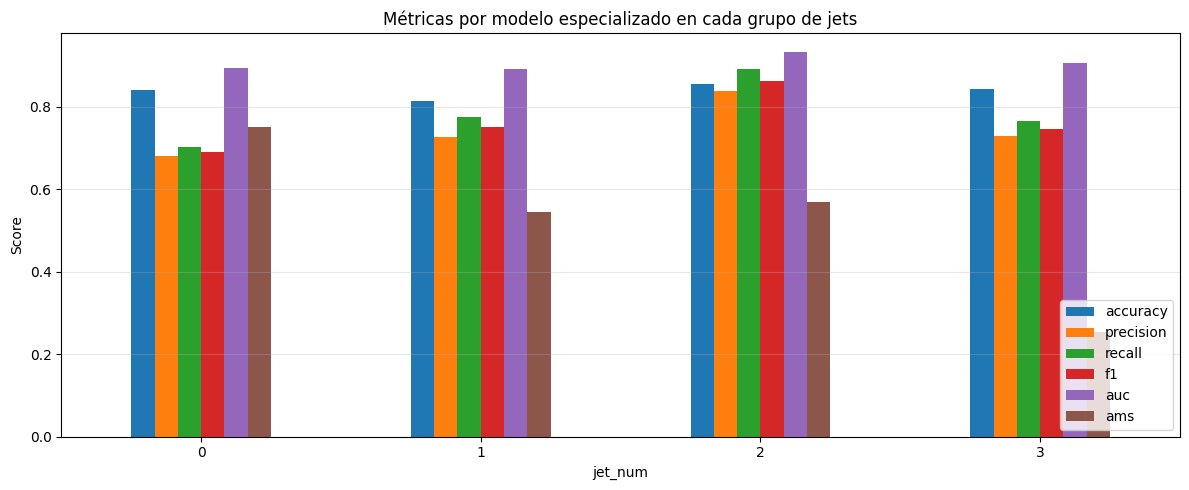

In [3]:
training_outputs = train_xgboost_by_jets(artifacts, xgb_params=BEST_XGB_PARAMS)

group_metrics_df = training_outputs["group_metrics_df"].copy()
overall_metrics_df = training_outputs["overall_metrics_df"].copy()
valid_predictions_df = training_outputs["valid_predictions_df"].copy()

print("Métricas por modelo especializado en cada jet:")
display(group_metrics_df.round(6))

print("Métrica global después de enrutar por PRI_jet_num:")
display(overall_metrics_df.round(6))

metric_plot_df = group_metrics_df.set_index("jet_num")[["accuracy", "precision", "recall", "f1", "auc", "ams"]]
metric_plot_df.plot(kind="bar", figsize=(12, 5), rot=0)
plt.ylabel("Score")
plt.title("Métricas por modelo especializado en cada grupo de jets")
plt.grid(axis="y", alpha=0.3)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()


In [4]:
project_root = find_project_root()
reference_path = project_root / "10.try" / "results" / "best_nn_vs_best_tree_comparison.csv"
reference_df = pd.read_csv(reference_path)
reference_tree_row = reference_df.loc[reference_df["model_family"] == "tree"].iloc[0]

current_tree_row = {
    "dataset": "xgboost_i3_tree_safe_mix_by_jets",
    "source": "11.Mezcla/03 + XGB por jet",
    "accuracy": float(overall_metrics_df.iloc[0]["accuracy"]),
    "precision": float(overall_metrics_df.iloc[0]["precision"]),
    "recall": float(overall_metrics_df.iloc[0]["recall"]),
    "f1": float(overall_metrics_df.iloc[0]["f1"]),
    "auc": float(overall_metrics_df.iloc[0]["auc"]),
    "ams": float(overall_metrics_df.iloc[0]["ams"]),
    "ams_threshold": float(overall_metrics_df.iloc[0]["ams_threshold"]),
}

comparison_df = pd.DataFrame([
    {
        "dataset": str(reference_tree_row["dataset"]),
        "source": str(reference_tree_row["source"]),
        "accuracy": float(reference_tree_row["accuracy"]),
        "precision": float(reference_tree_row["precision"]),
        "recall": float(reference_tree_row["recall"]),
        "f1": float(reference_tree_row["f1"]),
        "auc": float(reference_tree_row["auc"]),
        "ams": float(reference_tree_row["ams"]),
        "ams_threshold": float(reference_tree_row["ams_threshold"]),
    },
    current_tree_row,
])

base_row = comparison_df.iloc[0]
for metric in ["accuracy", "precision", "recall", "f1", "auc", "ams"]:
    comparison_df[f"delta_{metric}_vs_best_10try06"] = comparison_df[metric] - float(base_row[metric])

print("Comparación contra el mejor árbol de 10.try/06:")
display(comparison_df.round(6))


Comparación contra el mejor árbol de 10.try/06:


,dataset,source,accuracy,precision,recall,f1,auc,ams,ams_threshold,delta_accuracy_vs_best_10try06,delta_precision_vs_best_10try06,delta_recall_vs_best_10try06,delta_f1_vs_best_10try06,delta_auc_vs_best_10try06,delta_ams_vs_best_10try06
0,v2_physics_by_jet,same_best_xgboost_as_7_arboles,0.83612,0.743623,0.796311,0.769066,0.909888,1.107879,0.904876,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000
1,xgboost_i3_tree_safe_mix_by_jets,11.Mezcla/03 + XGB por jet,0.79624,0.918535,0.444847,0.599402,0.908090,1.083018,0.871616,-0.03988,0.174911,-0.351465,-0.169664,-0.001797,-0.024861


In [5]:
results_dir = project_root / "11.Mezcla" / "results"
models_dir = project_root / "11.Mezcla" / "models"
results_dir.mkdir(parents=True, exist_ok=True)
models_dir.mkdir(parents=True, exist_ok=True)

bundle_dir = models_dir / "i3_tree_safe_mix_by_jets_xgboost_bundle"
bundle_saved_paths = save_xgboost_by_jets_bundle(
    artifacts=artifacts,
    training_outputs=training_outputs,
    output_dir=bundle_dir,
    xgb_params=BEST_XGB_PARAMS,
)

comparison_csv_path = results_dir / "xgboost_i3_tree_safe_mix_by_jets_vs_best_10try06.csv"
group_metrics_csv_path = results_dir / "xgboost_i3_tree_safe_mix_by_jets_group_metrics.csv"
overall_metrics_csv_path = results_dir / "xgboost_i3_tree_safe_mix_by_jets_overall_metrics.csv"
comparison_df.to_csv(comparison_csv_path, index=False)
group_metrics_df.to_csv(group_metrics_csv_path, index=False)
overall_metrics_df.to_csv(overall_metrics_csv_path, index=False)

print(f"Bundle guardado en: {bundle_dir}")
print(f"Cantidad de archivos del bundle: {len(bundle_saved_paths)}")
print(f"CSV comparación: {comparison_csv_path}")
print(f"CSV group metrics: {group_metrics_csv_path}")
print(f"CSV overall metrics: {overall_metrics_csv_path}")


Bundle guardado en: /home/santig14/fing/taa/1_TallerAA/11.Mezcla/models/i3_tree_safe_mix_by_jets_xgboost_bundle
Cantidad de archivos del bundle: 15
CSV comparación: /home/santig14/fing/taa/1_TallerAA/11.Mezcla/results/xgboost_i3_tree_safe_mix_by_jets_vs_best_10try06.csv
CSV group metrics: /home/santig14/fing/taa/1_TallerAA/11.Mezcla/results/xgboost_i3_tree_safe_mix_by_jets_group_metrics.csv
CSV overall metrics: /home/santig14/fing/taa/1_TallerAA/11.Mezcla/results/xgboost_i3_tree_safe_mix_by_jets_overall_metrics.csv


In [6]:
test_scores_df = training_outputs["test_scores_df"].copy()
global_threshold = float(training_outputs["global_threshold_info"]["ams_threshold"])
submission_df = build_higgs_submission(
    event_ids=artifacts["global_test_event_id"],
    scores=test_scores_df["score"].to_numpy(),
    threshold=global_threshold,
)
submission_validation = validate_higgs_submission(submission_df)
submission_path = results_dir / f"higgs_submission_i3_tree_safe_mix_by_jets_xgboost_{datetime.now().strftime('%Y%m%d_%H%M%S')}.csv"
submission_df.to_csv(submission_path, index=False)

summary_txt_path = results_dir / "xgboost_i3_tree_safe_mix_by_jets_summary.txt"
summary_lines = [
    "# XGBoost por jets sobre i3_tree_safe_mix",
    "",
    f"Threshold global AMS: {global_threshold:.6f}",
    f"AMS validación: {float(overall_metrics_df.iloc[0]['ams']):.6f}",
    f"AUC validación: {float(overall_metrics_df.iloc[0]['auc']):.6f}",
    "",
    f"Bundle: {bundle_dir}",
    f"Submission: {submission_path}",
    f"Signal rows en submission: {submission_validation['signal_count']}",
    f"Background rows en submission: {submission_validation['background_count']}",
]
summary_txt_path.write_text("\n".join(summary_lines) + "\n")

print("Primeras filas del enrutamiento de inferencia sobre test:")
display(test_scores_df.head())
print("Resumen del submission generado:")
display(pd.DataFrame([submission_validation]))
print(f"Submission guardada en: {submission_path}")
print(f"Resumen textual guardado en: {summary_txt_path}")


Primeras filas del enrutamiento de inferencia sobre test:


,EventId,score,jet_num
0,350000,0.003971,0
1,350001,0.112632,1
2,350002,0.746217,0
3,350003,0.923675,0
4,350004,0.006657,3


Resumen del submission generado:


,rows,rank_min,rank_max,signal_count,background_count
0,550000,1,550000,89282,460718


Submission guardada en: /home/santig14/fing/taa/1_TallerAA/11.Mezcla/results/higgs_submission_i3_tree_safe_mix_by_jets_xgboost_20260502_014536.csv
Resumen textual guardado en: /home/santig14/fing/taa/1_TallerAA/11.Mezcla/results/xgboost_i3_tree_safe_mix_by_jets_summary.txt
